# Wpływ bliskości metra na ceny mieszkań w Warszawie

Badanie szacuje premię cenową za bliskość stacji metra metodą Propensity Score Matching, na ofertach sprzedaży mieszkań z czerwca 2024 roku. Notebook jest jedynym wejściem do obliczeń: logika liczbowa mieszka w `src/`, komórki poniżej ją wywołują i zapisują wyniki do `outputs/`.

Przebieg od góry do dołu trwa kilkanaście sekund i odtwarza wszystkie rysunki oraz tabele.

In [1]:
import sys
from pathlib import Path

# Korzen projektu wyznaczony szukaniem w gore, zeby notebook dzialal niezaleznie
# od katalogu roboczego, w ktorym wystartowalo jadro.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / 'src' / 'data_load.py').is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError(f'Nie znaleziono korzenia projektu startujac z {Path.cwd()}.')
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
print('PROJECT_ROOT:', PROJECT_ROOT)

import pandas as pd

from src import balance, config, data_load, diagnostics, psm, viz

config.ensure_output_dirs()

PROJECT_ROOT: D:\studia\ZEII\psm-metro-warszawa


## Dane i próba

Zbiór obejmuje oferty sprzedaży mieszkań z serwisu ogłoszeniowego, udostępnione na Kaggle. Z pliku wybierane są oferty warszawskie, a do każdej doliczana jest odległość euklidesowa do najbliższej z 38 stacji metra linii M1 i M2.

Braki w zmiennych modelu usuwane są listowo, bo algorytm najbliższego sąsiada liczy odległość na pełnym wektorze cech. Komórka poniżej wypisuje, ile próby ubywa na każdym kroku i która zmienna za to odpowiada.

In [2]:
sample = data_load.build_model_sample()
model = sample['model']
features = sample['features']
treatment = sample['treatment']

counts = pd.Series(sample['counts'], name='Wartość', dtype=object).to_frame()
counts.index.name = 'Krok'
counts.to_csv(config.TABLES / 'licznosci_proby.csv', encoding='utf-8')
print(counts.to_string())

missing = sample['missing_share']
missing = missing[missing > 0].round(2).rename('Braki (%)').to_frame()
missing.index.name = 'Zmienna'
missing.to_csv(config.TABLES / 'braki_danych.csv', encoding='utf-8')
print()
print(missing.to_string())

raw_difference = data_load.raw_difference(model)
print()
print(f'Roznica surowa cen: {raw_difference:.1f} zl/m2')

                      Wartość
Krok                         
oferty_w_pliku          21501
oferty_w_miescie         6962
stacje_metra               38
po_filtrze_cen           6962
po_usunieciu_brakow      2868
proba_modelowa           2046
grupa_eksperymentalna     615
grupa_kontrolna          1431
zmienne_kontrolne          23
utracony_udzial          58.8

                      Braki (%)
Zmienna                        
buildingMaterial          43.36
type                      22.82
floor                     14.45
buildYear                  9.34
hasElevator                3.86
collegeDistance            2.08
floorCount                 0.93
restaurantDistance         0.24
pharmacyDistance           0.20
clinicDistance             0.20
kindergartenDistance       0.06
postOfficeDistance         0.04

Roznica surowa cen: 2366.1 zl/m2


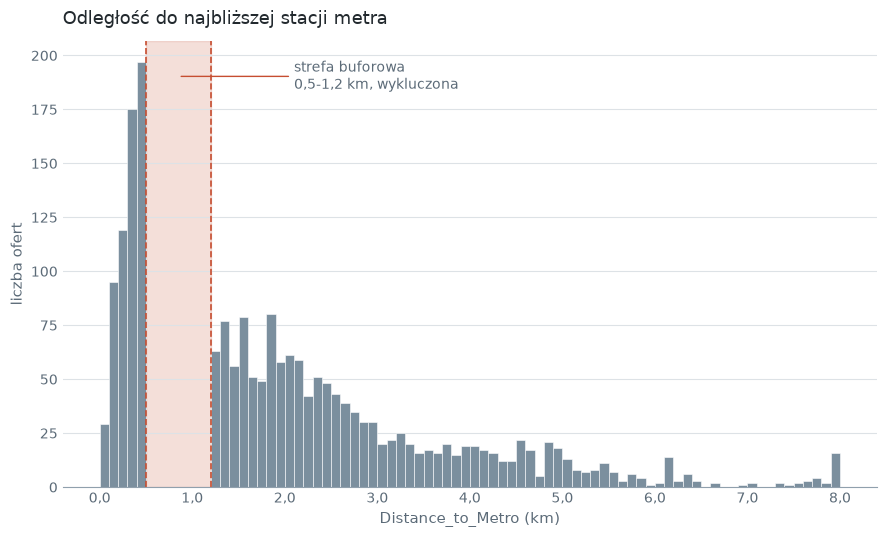

In [3]:
viz.plot_buffer_zone(model, save=True);

## Propensity score i dopasowanie

Propensity score to prawdopodobieństwo warunkowe, że lokal leży blisko metra, przy danym wektorze jego cech fizycznych. Zmienne ciągłe są wcześniej standaryzowane, bo dopasowanie korzysta z metryki euklidesowej.

Badanie przechodzi przez 6 wariantów: dwie formy funkcyjne, dwie proporcje dopasowania i wariant z ograniczeniem calipera. Caliper odrzuca pary, w których najdalszy przyjęty sąsiad wypada poza 0,2 odchylenia standardowego propensity score.

In [4]:
scaled = psm.standardise(features)
scenarios = psm.run_all_scenarios(scaled, treatment, model)

scenarios['table'].to_csv(config.TABLES / 'wyniki_wariantow.csv',
                          index=False, encoding='utf-8')
print(scenarios['table'].to_string(index=False))

main = scenarios['results'][config.MAIN_SCENARIO]
print()
print(f'Wariant interpretowany: {config.MAIN_SCENARIO}')
print(f'  limit calipera: {main["matched"]["caliper_limit"]:.5f}')
print(f'  pary odrzucone przez caliper: {main["matched"]["dropped"]}')
print(f'  ATT: {main["att_pln"]:.0f} zl/m2, czyli {main["efekt_procentowy"]:.2f}%')
print(f'  95% przedzial ufnosci: '
      f'[{main["ci_dolny_procent"]:.2f}%; {main["ci_gorny_procent"]:.2f}%]')
print(f'  p-value (test t dla par): {main["p_value"]:.2e}')
print(f'  udzial roznicy surowej wyjasniony bliskoscia metra: '
      f'{100 * main["att_pln"] / raw_difference:.1f}%')

              Wariant    N  Różnica surowa (zł/m2)  ATT (zł/m2)  ATT (%)  95% CI dolny (%)  95% CI górny (%)            p  Liczba par
         Logit 1-to-1 2046                    2366          183     1.43             -0.67              3.57 1.832074e-01         615
        Probit 1-to-1 2046                    2366          689     3.51              1.40              5.68 1.118364e-03         615
         Logit 1-to-4 2046                    2366          331     2.56              0.96              4.18 1.697482e-03         615
        Probit 1-to-4 2046                    2366          319     2.55              0.90              4.22 2.459454e-03         615
 Logit 1-to-4 Caliper 2046                    2366          735     4.52              2.78              6.29 3.530516e-07         509
Probit 1-to-4 Caliper 2046                    2366          717     4.49              2.68              6.33 1.157481e-06         510

Wariant interpretowany: Logit 1-to-4 Caliper
  limit calipera

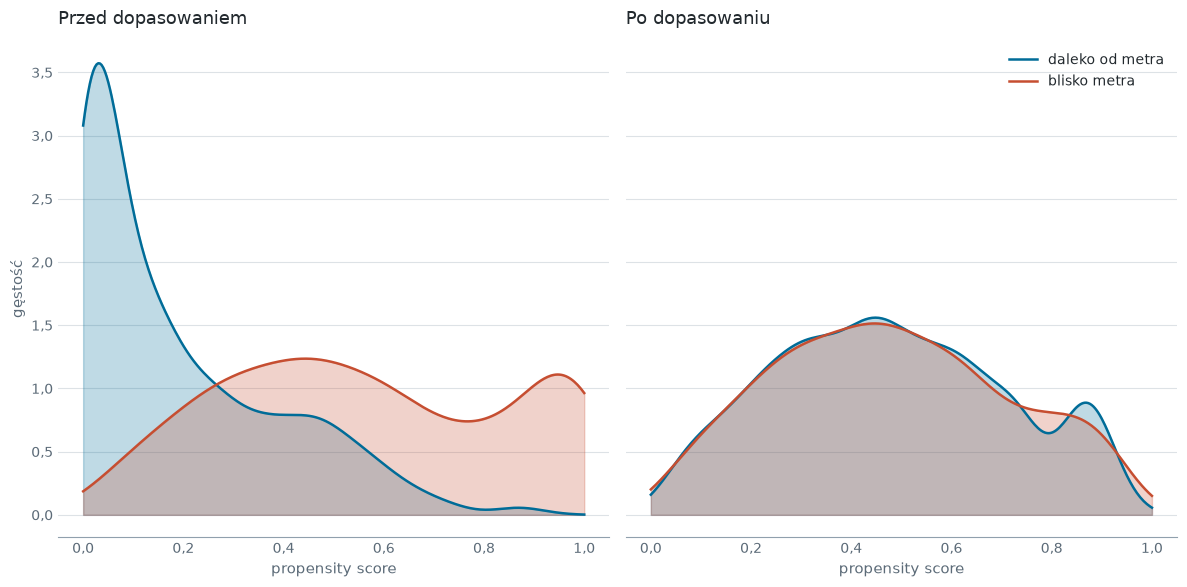

In [5]:
viz.plot_propensity_overlap(main['matched'], main['scores'], treatment, save=True);

## Zbalansowanie zmiennych kontrolnych

Dopasowanie ma sens tylko wtedy, gdy po jego wykonaniu grupy przestają się różnić cechami fizycznymi. Miarą jest standaryzowana różnica średnich (SMD): licznik liczony jest na grupach dopasowanych, mianownik na pierwotnych, żeby zmniejszenie wariancji przez samo dopasowanie nie udawało pogorszenia balansu.

Progi przyjęto za Rubinem (2001): 0,1 jako poziom docelowy, 0,25 jako granicę akceptowalną.

In [6]:
smd = balance.smd_table(model, main['matched'])
smd.round(4).to_csv(config.TABLES / 'zbalansowanie_smd.csv',
                    index=False, encoding='utf-8')
print(smd.round(4).to_string(index=False))

summary = balance.balance_summary(smd)
print()
print(f'Zmiennych kontrolnych: {summary["zmiennych"]}')
print(f'Najwyzszy SMD przed dopasowaniem: {summary["max_smd_przed"]:.3f}')
print(f'Najwyzszy SMD po dopasowaniu: {summary["max_smd_po"]:.3f} '
      f'({summary["zmienna_max_po"]})')
print(f'Ponizej progu {config.SMD_TARGET}: {summary["ponizej_progu"]} '
      f'z {summary["zmiennych"]}')
print(f'Powyzej granicy {config.SMD_LIMIT}: {summary["ponad_limitem"]}')

                      Zmienna  SMD przed  SMD po  Redukcja (%)
                     poiCount     1.1370  0.0145       98.7243
               clinicDistance     0.9822  0.0296       96.9913
              collegeDistance     0.9743  0.0692       92.8934
               centreDistance     0.9165  0.0711       92.2447
               schoolDistance     0.8110  0.0311       96.1710
                    buildYear     0.7877  0.0028       99.6383
           postOfficeDistance     0.7506  0.0213       97.1566
             pharmacyDistance     0.7398  0.0019       99.7494
           restaurantDistance     0.6589  0.0161       97.5630
                type_tenement     0.5788  0.0341       94.1076
         kindergartenDistance     0.4206  0.0232       94.4804
               hasStorageRoom     0.4140  0.0071       98.2908
                  hasSecurity     0.3214  0.0736       77.1108
                   floorCount     0.3169  0.0106       96.6439
                   hasBalcony     0.2869  0.0676       

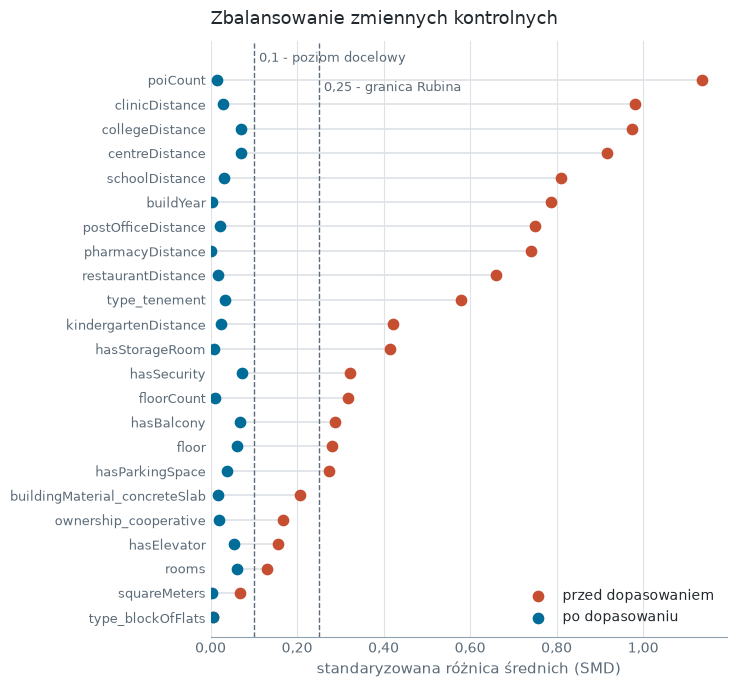

In [7]:
viz.plot_love(smd, save=True);

## Oszacowania ATT

ATT jest średnią z różnic parowych, nie różnicą średnich: przy dopasowaniu ze zwracaniem te dwie wielkości nie są sobie równe, bo ten sam lokal kontrolny wchodzi do wielu par z różnymi wagami. Istotność liczy test t-Studenta dla par, a przedział ufności pochodzi z tego samego błędu standardowego różnic parowych.

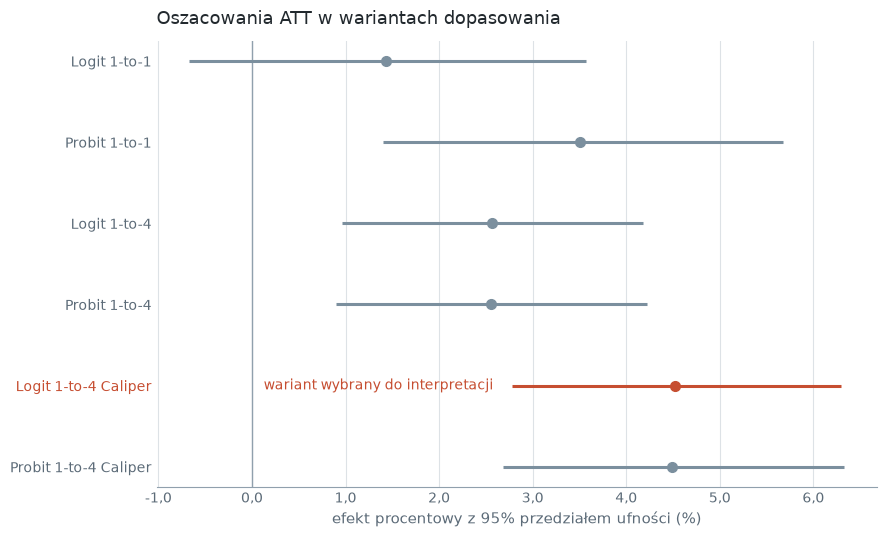

In [8]:
viz.plot_scenarios(scenarios['table'], save=True);

## Heterogeniczność efektu

Podział na podgrupy dotyczy lokali z grupy eksperymentalnej; ich sobowtóry pozostają te same co w oszacowaniu głównym, więc podgrupy rozkładają efekt główny, a nie liczą go od nowa na zawężonej próbie.

In [9]:
subgroups = psm.subgroup_effects(main['matched'])
subgroups.to_csv(config.TABLES / 'podgrupy_material.csv',
                 index=False, encoding='utf-8')
print(subgroups.to_string(index=False))

                Podgrupa   N  Efekt (%)
            wielka płyta 138      -7.25
cegła i nowe budownictwo 371       9.28


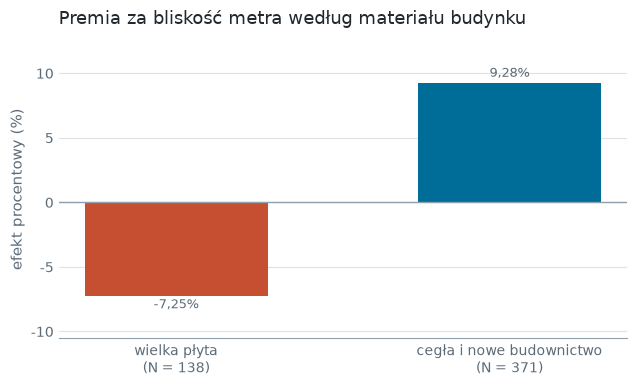

In [10]:
viz.plot_material_subgroups(subgroups, save=True);

## Współliniowość zmiennych kontrolnych

Czynnik inflacji wariancji liczony jest na próbie modelowej, czyli po odrzuceniu strefy buforowej - to ten zbiór wchodzi do estymacji propensity score.

In [11]:
vif = diagnostics.vif_table(features)
vif.round(2).to_csv(config.TABLES / 'vif.csv', index=False, encoding='utf-8')
print(vif.round(2).to_string(index=False))

vif_info = diagnostics.vif_summary(vif)
print()
print(f'Najwyzszy VIF: {vif_info["max_vif"]:.2f} ({vif_info["zmienna"]})')
print(f'Zmiennych powyzej progu {vif_info["prog"]:.0f}: {vif_info["ponad_progiem"]}')

correlations = diagnostics.correlation_matrix(features)
print()
print(diagnostics.strongest_correlations(correlations).round(3).to_string(index=False))

                      Zmienna  VIF
                    buildYear 6.27
                type_tenement 5.13
                 squareMeters 3.86
                        rooms 3.67
                   floorCount 2.86
buildingMaterial_concreteSlab 2.58
            type_blockOfFlats 2.55
               centreDistance 2.26
               clinicDistance 2.17
              collegeDistance 2.10
                        floor 2.00
                     poiCount 1.98
           postOfficeDistance 1.95
             pharmacyDistance 1.90
           restaurantDistance 1.78
                  hasElevator 1.77
               schoolDistance 1.77
               hasStorageRoom 1.58
         kindergartenDistance 1.44
              hasParkingSpace 1.25
        ownership_cooperative 1.23
                   hasBalcony 1.16
                  hasSecurity 1.15

Najwyzszy VIF: 6.27 (buildYear)
Zmiennych powyzej progu 10: 0

        Zmienna A                     Zmienna B  Korelacja
            rooms                  sq

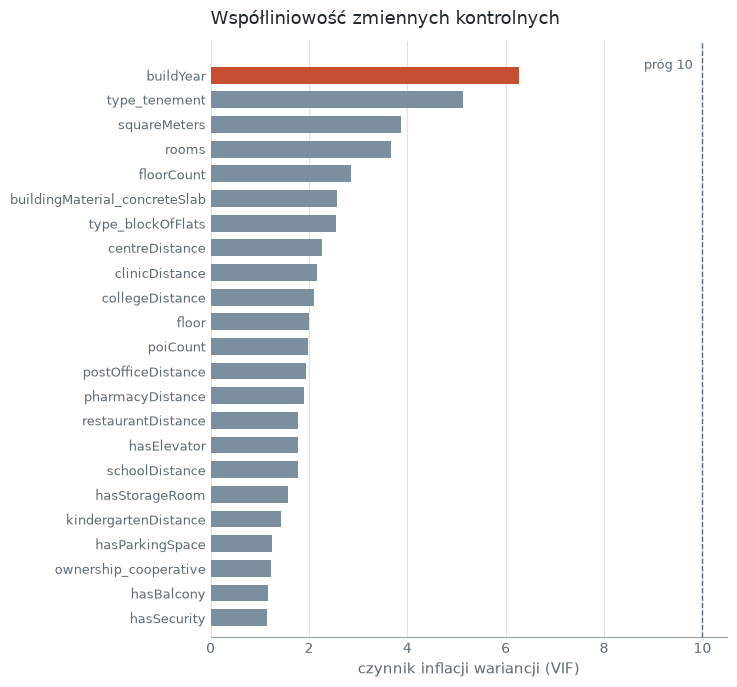

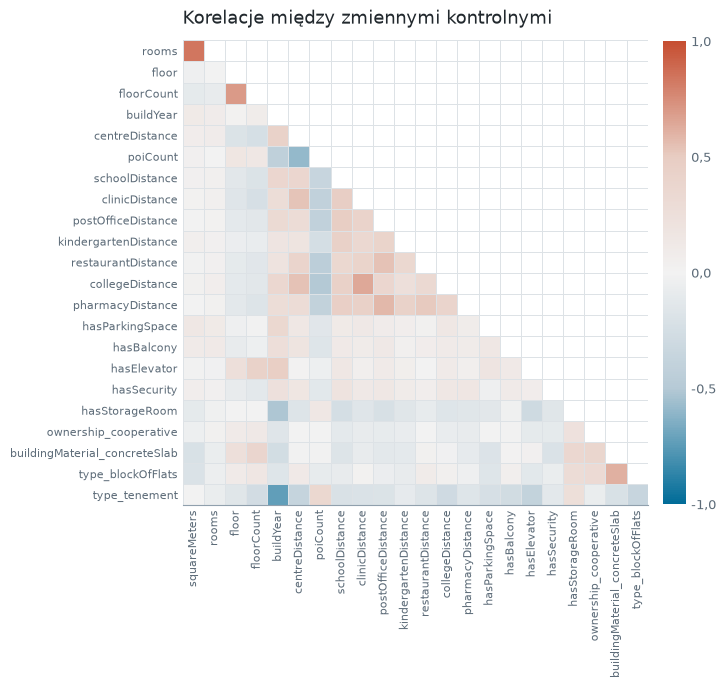

In [12]:
viz.plot_vif(vif, save=True);
viz.plot_correlation(correlations, save=True);